In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10

(X_train, y_train), (X_test, y_test) = cifar10.load_data()

print("Training data shape:", X_train.shape, "Labels shape:", y_train.shape)
print("Test data shape:", X_test.shape, "Labels shape:", y_test.shape)
print("First 5 training labels:", y_train[:5].ravel())

Matplotlib is building the font cache; this may take a moment.


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2508s 15us/step
Training data shape: (50000, 32, 32, 3) Labels shape: (50000, 1)
Test data shape: (10000, 32, 32, 3) Labels shape: (10000, 1)
First 5 training labels: [6 9 9 4 1]


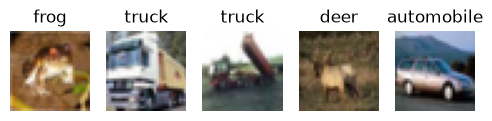

In [2]:
class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

plt.figure(figsize=(6, 2))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')
plt.show()

In [3]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

y_train_flat = y_train.ravel()
y_test_flat = y_test.ravel()

print("After flattening:", X_train_flat.shape, y_train_flat.shape)

After flattening: (50000, 3072) (50000,)


In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_clf.fit(X_train_flat, y_train_flat)

y_pred_rf = rf_clf.predict(X_test_flat)
acc_rf = accuracy_score(y_test_flat, y_pred_rf)
print(f"Random Forest test accuracy: {acc_rf:.4f}")

Random Forest test accuracy: 0.4655


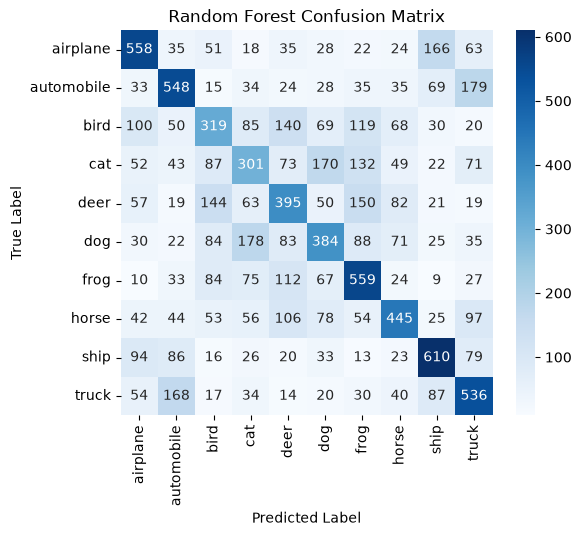

In [5]:
import seaborn as sns

cm_rf = confusion_matrix(y_test_flat, y_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Random Forest Confusion Matrix")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.show()

In [6]:
X_train_flat = (X_train_flat - 0.5) * 2.0
X_test_flat = (X_test_flat - 0.5) * 2.0

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input

model = Sequential()
model.add(Input(shape=(3072,)))
model.add(Dense(512, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(128, activation='relu'))
model.add(Dense(10, activation='softmax'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,738,890 (6.63 MB)

 Trainable params: 1,738,890 (6.63 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(X_train_flat, y_train_flat,
                    epochs=25, batch_size=128,
                    validation_split=0.1, verbose=2)

Epoch 1/25
352/352 - 3s - 8ms/step - accuracy: 0.3371 - loss: 1.8566 - val_accuracy: 0.4266 - val_loss: 1.6430
Epoch 2/25
352/352 - 2s - 7ms/step - accuracy: 0.4055 - loss: 1.6729 - val_accuracy: 0.4514 - val_loss: 1.5629
Epoch 3/25
352/352 - 2s - 7ms/step - accuracy: 0.4374 - loss: 1.5860 - val_accuracy: 0.4716 - val_loss: 1.5106
Epoch 4/25
352/352 - 2s - 6ms/step - accuracy: 0.4603 - loss: 1.5227 - val_accuracy: 0.4854 - val_loss: 1.4814
Epoch 5/25
352/352 - 2s - 7ms/step - accuracy: 0.4775 - loss: 1.4731 - val_accuracy: 0.4938 - val_loss: 1.4349
Epoch 6/25
352/352 - 2s - 6ms/step - accuracy: 0.4904 - loss: 1.4316 - val_accuracy: 0.4984 - val_loss: 1.4391
Epoch 7/25
352/352 - 2s - 6ms/step - accuracy: 0.5002 - loss: 1.4009 - val_accuracy: 0.5146 - val_loss: 1.3979
Epoch 8/25
352/352 - 2s - 6ms/step - accuracy: 0.5126 - loss: 1.3684 - val_accuracy: 0.5192 - val_loss: 1.3707
Epoch 9/25
352/352 - 2s - 7ms/step - accuracy: 0.5238 - loss: 1.3390 - val_accuracy: 0.5298 - val_loss: 1.3496
E

In [9]:
test_loss, test_accuracy = model.evaluate(X_test_flat, y_test_flat, verbose=0)
print(f"Neural Network test accuracy: {test_accuracy:.4f}")
print(f"Random Forest test accuracy:  {acc_rf:.4f}")

Neural Network test accuracy: 0.5527
Random Forest test accuracy:  0.4655


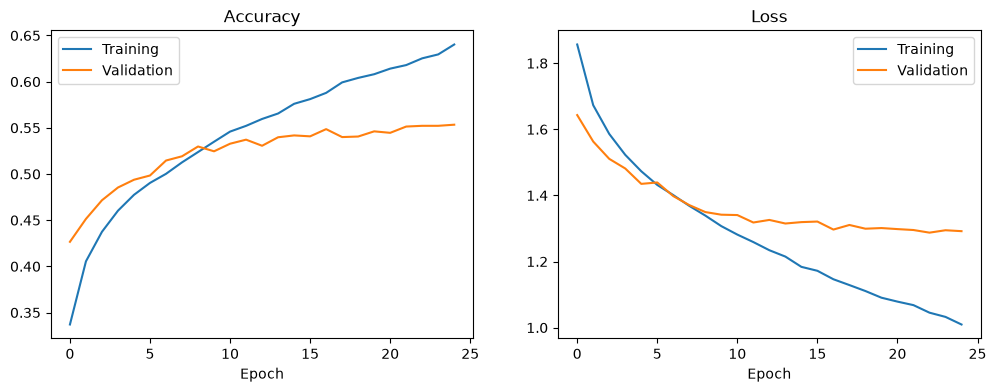

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 865us/step


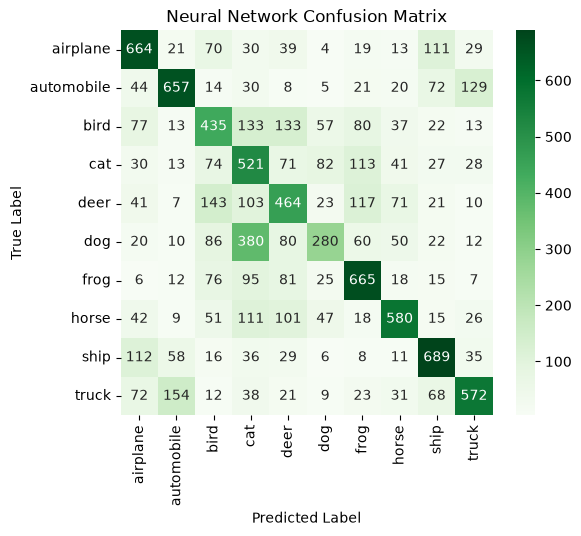

In [11]:
y_pred_prob = model.predict(X_test_flat)
y_pred_classes = np.argmax(y_pred_prob, axis=1)

cm_ann = confusion_matrix(y_test_flat, y_pred_classes)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_ann, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Neural Network Confusion Matrix")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.show()

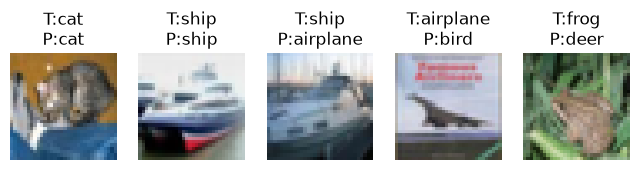

In [12]:
samples = [0, 1, 2, 3, 4]
plt.figure(figsize=(8, 2))
for i, idx in enumerate(samples):
    plt.subplot(1, len(samples), i + 1)
    plt.imshow(X_test[idx])
    plt.title(f"T:{class_names[y_test_flat[idx]]}\nP:{class_names[y_pred_classes[idx]]}")
    plt.axis('off')
plt.show()